In [1]:
packages <- c("ggplot2", "patchwork")
for (pkg in packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(pkg, character.only = TRUE)))
}
git_root <- system("git rev-parse --show-toplevel", intern = TRUE)

In [2]:
final_plot_file_path <- file.path(git_root, "figures", "assembled_figures","figures", "final_plot.png")
# make the parent directory if it does not exist
if (!dir.exists(dirname(final_plot_file_path))) {
  dir.create(dirname(final_plot_file_path), recursive = TRUE)
}

In [3]:
pdo_workflow <- file.path(git_root,"figures/workflow_figures/figures/pdo_pipeline_figure.png")
cell_painting_montage <- file.path(git_root,"figures/assembled_figures/imported_media/cell_painting_assay_montage_NF0014_T1_C4-2.png")
featurization_types <- file.path(git_root,"figures/assembled_figures/imported_media/Feature_types_tall.png")
ibp_workflow <- file.path(git_root,"figures/workflow_figures/figures/profiling_workflow.png")


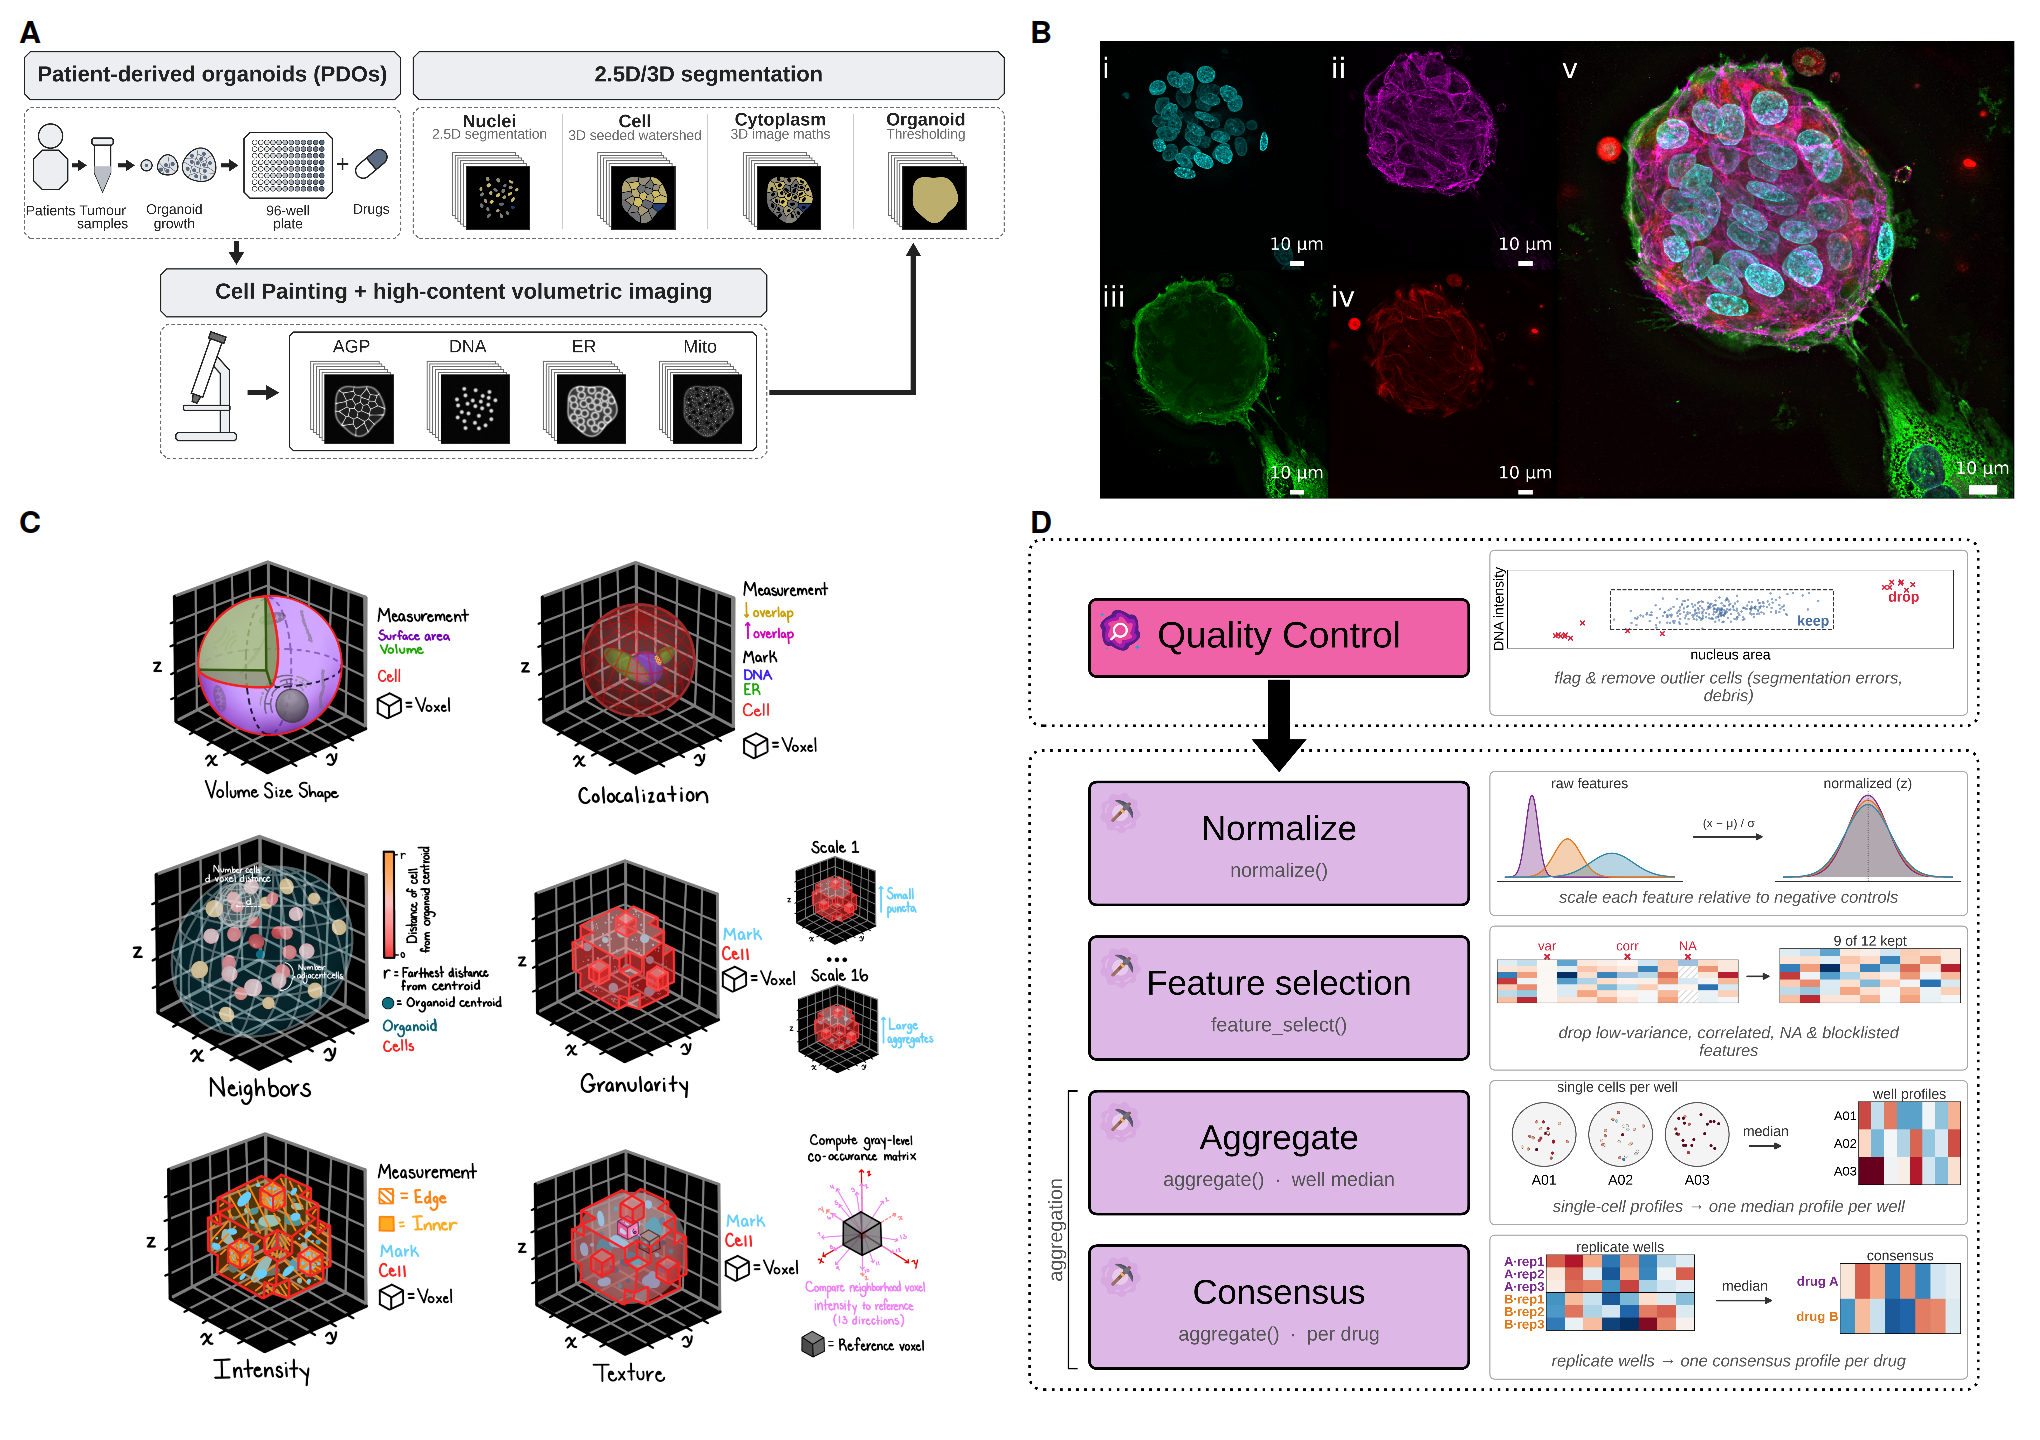

In [4]:
width <- 17
height <- 12
options(repr.plot.width = width, repr.plot.height = height)
# patchwork layout
layout <- "
AB
CD
CD
"

# B's source image has no blank margin at its top-left corner (unlike A, C, D),
# so the automatic patchwork tag has nowhere to sit without overlapping the
# image content. Pad just that image with white space before rasterizing it,
# rather than changing how any panel is laid out.
pad_top_left <- function(img, pad_frac = 0.07) {
    d <- dim(img)
    h <- d[1]; w <- d[2]; chans <- d[3]
    pad_h <- round(h * pad_frac)
    pad_w <- round(w * pad_frac)
    out <- array(1, dim = c(h + pad_h, w + pad_w, chans))
    out[(pad_h + 1):(h + pad_h), (pad_w + 1):(w + pad_w), ] <- img
    out
}

pA <- wrap_elements(full = grid::rasterGrob(png::readPNG(pdo_workflow), interpolate = TRUE))
pB <- wrap_elements(full = grid::rasterGrob(pad_top_left(png::readPNG(cell_painting_montage)), interpolate = TRUE))
pC <- wrap_elements(full = grid::rasterGrob(png::readPNG(featurization_types), interpolate = TRUE))
pD <- wrap_elements(full = grid::rasterGrob(png::readPNG(ibp_workflow), interpolate = TRUE))

final_plot <- (
    wrap_plots(A = pA, B = pB, C = pC, D = pD, design = layout)
    + plot_annotation(tag_levels = 'A')
    & theme(plot.tag = element_text(face = "bold", size = 18))
)
# save the final plot
ggsave(final_plot_file_path, plot = final_plot, width = width, height = height, dpi = 600)
final_plot